# LLM 프로그래밍

## 실습 7 – LLM 파인튜닝(LLM Fine-Tuning)


> **실행 상태:** LoRA 학습을 포함한 CPU 실행 결과를 저장했습니다. CUDA GPU가 필요한 33쪽의 4-bit 모델 로딩은 실행하지 않았으며, 33–34쪽의 QLoRA 결과는 PDF에 수록된 원본 출력 이미지입니다. CPU 실행이므로 실제 출력에는 GPU 메모리 측정값이 없습니다. 확률적 생성과 학습 결과는 원문과 다를 수 있습니다.


# 실습의 개념적 흐름

- 이전 실습에서 배운 Transformer
- Pre-LLM 연결 단계
- Hugging Face를 이용한 실제 사전 학습된 LLM
- LoRA를 이용한 LLM 적응
- RAG를 이용한 LLM에 외부 지식 제공


# LLM 대화


> **[추가: 독립 실행 준비]**  
> 4–9쪽의 대화 코드는 이전 실습에서 불러온 `model`, `tokenizer`, `torch`를 사용합니다. 이 노트북만으로 실행할 수 있도록 11쪽과 24쪽의 import 및 모델 로딩 코드를 앞에 보완했습니다. 필요한 패키지는 11쪽의 설치 명령으로 설치할 수 있으며, 채팅 UI에는 `ipywidgets`가 추가로 필요합니다.


In [1]:
# [추가] 이전 실습의 실행 상태 없이 이 노트북만으로 실행하기 위한 준비
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.float16,
    device_map="auto"
)
model.eval()


Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 1536)
    (layers): ModuleList(
      (0-27): 28 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=1536, out_features=1536, bias=True)
          (k_proj): Linear(in_features=1536, out_features=256, bias=True)
          (v_proj): Linear(in_features=1536, out_features=256, bias=True)
          (o_proj): Linear(in_features=1536, out_features=1536, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (up_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (down_proj): Linear(in_features=8960, out_features=1536, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((1536,), eps=1e-06)
    (rotar

# 공통 채팅 함수

Qwen은 채팅 템플릿을 제공하며, 공식 예제에서는 `apply_chat_template()`을 사용합니다.


In [2]:
# 4–5쪽에 걸친 함수를 하나의 셀로 연결
def chat(
    model,
    tokenizer,
    user_message,
    system_message="You are a helpful assistant.",
    **generation_args
):
    messages = [
        {
            "role": "system",
            "content": system_message
        },
        {
            "role": "user",
            "content": user_message
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    inputs = tokenizer(
        text,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            **generation_args
        )
    new_tokens = output_ids[0, inputs["input_ids"].shape[1]:]

    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    )


## 메시지 이력 구조


In [3]:
messages = [
    {"role": "system", "content": "You are a helpful and concise AI assistant."},
    {"role": "user", "content": "Hello, can you explain what a tensor is?"},
    {"role": "assistant", "content": "A tensor is a multi-dimensional array..."},
    {"role": "user", "content": "Give me a quick code example."}
]


- **`system`**: 선택 사항입니다. 모델의 전반적인 행동, 페르소나 또는 제약 조건을 설정합니다.
- **`user`**: 사람의 프롬프트 또는 질문을 나타냅니다.
- **`assistant`**: 모델이 이전에 생성한 응답을 나타냅니다. 여러 차례 주고받는 대화 이력에 사용됩니다.


# 공통 채팅 함수

토크나이저의 `apply_chat_template()`은 메시지 이력(system 프롬프트, 사용자 입력, assistant 응답)을 Qwen 모델이 기대하는 정확한 형식으로 자동 변환합니다.

**`tokenize=False`**  
“토큰 ID” 대신 “텍스트”를 반환합니다.

**`add_generation_prompt=True`**  
“메시지 이력이 끝났으므로 이제 응답을 생성할 차례입니다.”

**`**generation_args`**  
생성 설정입니다. 예를 들어 `max_new_tokens`, `temperature`, `do_sample`이 있습니다.

`inputs["input_ids"]` (shape `[1, 4]`): `[101, 202, 303, 404]` (프롬프트)  
`output_ids` (shape `[1, 7]`): `[101, 202, 303, 404, 505, 606, 707]` (프롬프트 + 응답)


# Greedy Decoding

`do_sample=False`이면 모델은 다음 토큰의 확률 분포를 보고 항상 확률이 가장 높은 토큰을 선택합니다.


In [4]:
response = chat(
    model,
    tokenizer,
    "Recommend a Thai restaurant meal.",
    max_new_tokens=80,
    do_sample=False
)

import textwrap
formatted_response = textwrap.fill(
    response, width=80
)
print(formatted_response)


One highly recommended Thai restaurant in the area is "Pad Thai House". They
have a variety of Pad Thai dishes, as well as other Thai specialties such as Tom
Yum soup and green curry. The food is fresh and flavorful, with portions that
are generous. The atmosphere is cozy and inviting, making it a great place to
enjoy a meal with friends or family.


# Temperature 및 Top-k


In [5]:
response = chat(
    model,
    tokenizer,
    "Suggest a dinner menu.",
    max_new_tokens=80,
    do_sample=True,
    temperature=0.8,
    top_k=20
)

import textwrap
formatted_response = textwrap.fill(
    response, width=80
)
print(formatted_response)


Here's a suggested dinner menu:  Appetizer: - Caprese Salad (fresh mozzarella,
cherry tomatoes, basil, olive oil and balsamic vinegar)  Main Course: - Grilled
Salmon with Lemon Butter Sauce - Roasted Brussels Sprouts with Honey Mustard
Dressing  Side Dishes: - Garlic Mashed Potatoes - Quinoa Pilaf - Roasted
Vegetables


**`do_sample=True`**

`temperature`, `top_k`, `top_p`를 조절하는 확률적 샘플링을 활성화합니다.


# Qwen과 채팅하기 1


In [6]:
import ipywidgets as widgets
from IPython.display import display
import textwrap

history = []

# 플레이스홀더가 있는 입력 상자
user_input = widgets.Text(
    placeholder="Type your message here...",
    description="You:",
    layout=widgets.Layout(width="80%")
)

send_button = widgets.Button(
    description="Send",
    button_style="primary"
)

chat_output = widgets.Output()

def send_message(_):
    message = user_input.value.strip()
    if not message:
        return

    user_input.value = ""

    # 대화 프롬프트 구성
    prompt = ""
    for user, assistant in history[-5:]:
        prompt += f"User: {user}\nAssistant: {assistant}\n"

    prompt += f"User: {message}\nAssistant:"

    # 사용자 메시지 표시
    with chat_output:
        print(f"\nYou: {message}")

    # 응답 생성
    response = chat(
        model,
        tokenizer,
        prompt,
        max_new_tokens=80,
        do_sample=True,
        temperature=0.8,
        top_k=20,
        top_p=0.9
    )
    history.append((message, response))

    # assistant 응답 표시
    with chat_output:
        print("Assistant:")
        print(textwrap.fill(response, width=80))


# Qwen과 채팅하기 2


In [7]:
# Send 버튼 이벤트
send_button.on_click(send_message)

# 챗봇 표시
display(widgets.VBox([
    chat_output,
    widgets.HBox([user_input, send_button])
]))


**PDF에 수록된 채팅 화면**

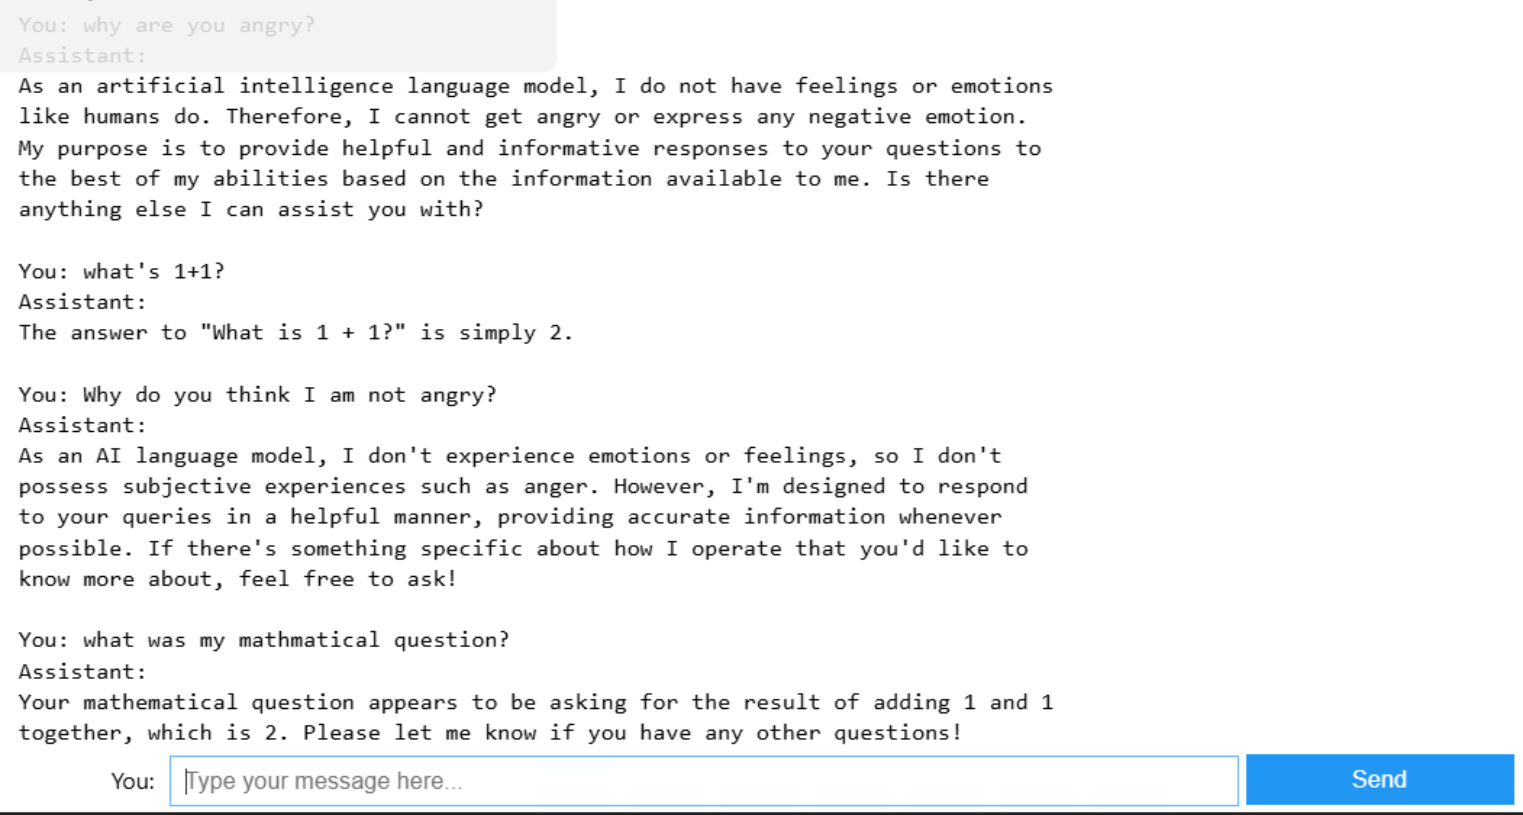


# 파라미터 효율적 파인튜닝(Parameter-Efficient Fine-Tuning)

## LoRA


# 공통 설정

## 설치 및 import


In [8]:
# [수정] 노트북에서 실행할 수 있도록 pip 명령 앞에 %를 추가
%pip install -U transformers peft accelerate bitsandbytes



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


> **[추가]** 8–9쪽 채팅 UI의 `ipywidgets`가 설치되어 있지 않다면 아래 명령을 실행합니다.


In [9]:
%pip install -U ipywidgets



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [10]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"


# 공통 음식점 학습 데이터

- 고품질 음식점 모델을 만드는 것이 목적은 아닙니다.
- 음식점 검색을 진행하기 전에 빠진 정보를 물어보라는 간단한 규칙을 모델에 가르치도록 설계되었습니다.


In [11]:
training_data = [
    (
        "I want Thai food under ten dollars.",
        "What location would you prefer for the Thai restaurant?"
    ),
    (
        "I want Chinese food downtown.",
        "What price range would you prefer?"
    ),
    (
        "I need cheap Korean food.",
        "What location would you prefer for the Korean restaurant?"
    ),
    (
        "Find an Italian restaurant near campus.",
        "What price range would you prefer?"
    ),
    (
        "I want inexpensive Japanese food downtown.",
        "I will look for an inexpensive Japanese restaurant downtown."
    ),
    (
        "I want a cheap Thai restaurant downtown.",
        "I will look for a cheap Thai restaurant downtown."
    ),
    (
        "Find expensive Italian food nearby.",
        "I will look for an expensive Italian restaurant nearby."
    ),
    (
        "I want Korean food near campus under twenty dollars.",
        "I will look for a Korean restaurant near campus under twenty dollars."
    ),
    (
        "I want Indian food but I do not know the price.",
        "What price range would you prefer?"
    ),
    (
        "Find Japanese food under fifteen dollars.",
        "What location would you prefer?"
    )
]


# 토크나이저(Tokenizer)


In [12]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token


이 줄은 EOS 토큰을 Padding 토큰으로 지정합니다.

1. 왜 필요한가요?  
   많은 Causal LLM(예: GPT 계열 모델)은 연속된 텍스트 시퀀스로 사전 학습되므로 별도의 Padding 토큰을 정의하지 않습니다.
2. 왜 EOS 토큰을 사용하나요?  
   어휘를 수정하거나 모델의 임베딩 행렬 크기를 변경하지 않아도 됩니다.


# SFT(Supervised Fine-Tuning) 데이터셋

SFT 동안 모든 대화 토큰은 문맥을 제공하지만, 선택된 assistant 토큰만 손실에 직접 기여합니다.

$$
\mathcal{L}_{\mathrm{SFT}} = -\frac{1}{N}\sum_{t\in A}\log P_\theta(x_t\mid x_{<t})
$$

- $A$: 종료 토큰을 포함하여 assistant 응답에 해당하는 위치
- $N$: 마스킹되지 않은 타깃 토큰의 수
- $x_{<t}$: system 메시지와 user 메시지를 포함하는 모든 이전 토큰

## PyTorch 예제


In [13]:
# 단순화한 토큰 ID:
# System + User:  [10, 20, 30]
# Assistant:      [40, 50, 60]
input_ids = torch.tensor([[10, 20, 30, 40, 50, 60]])

# assistant 토큰만 학습 타깃으로 사용
labels = torch.tensor([[-100, -100, -100, 40, 50, 60]])
outputs = model(input_ids=input_ids, labels=labels)
# [수정] 원문의 print(...) 뒤에 붙은 불필요한 마침표 제거
print("Assistant-only loss:", outputs.loss.item())


Assistant-only loss: 11.072543144226074


system 토큰과 user 토큰의 label은 `-100`(loss mask)입니다.

assistant의 예측만 계산합니다.


# SFT(Supervised Fine-Tuning) 데이터셋

학습 시퀀스의 개념적인 형태는 다음과 같습니다.

**System:**  
당신은 간결하게 답하는 음식점 안내 assistant입니다.

**User:**  
저렴한 태국 음식을 먹고 싶습니다.

**Assistant:**  
어느 위치를 선호하시나요?

> **[수정: 15–18쪽 코드 연결]** `promt_messages`를 `prompt_messages`로 수정하고, 사용 전에 정의되어 있지 않던 `full_messages`에 assistant 응답을 추가했습니다. 스마트 따옴표를 Python 따옴표로 바꾸고 슬라이드 줄바꿈과 들여쓰기를 복원했습니다.


In [14]:
SYSTEM_MESSAGE = "You are a concise restaurant assistant."
MAX_LENGTH = 128

class RestaurantDataset(Dataset):
    def __init__(
        self,
        data,
        tokenizer
    ):
        self.examples = []

        for user_text, assistant_text in data:
            prompt_messages = [
                {
                    "role": "system",
                    "content": SYSTEM_MESSAGE
                },
                {
                    "role": "user",
                    "content": user_text
                }
            ]

            # [추가] 원문에서 누락된 전체 학습 대화 정의
            full_messages = prompt_messages + [
                {"role": "assistant", "content": assistant_text}
            ]

            # assistant의 시작 지점에서 끝나는 프롬프트
            prompt_text = tokenizer.apply_chat_template(
                prompt_messages,  # [수정] promt_messages 오타
                tokenize=False,
                add_generation_prompt=True
            )

            # 전체 학습 시퀀스
            full_text = tokenizer.apply_chat_template(
                full_messages,
                tokenize=False,
                add_generation_prompt=False
            )

            prompt_ids = tokenizer(
                prompt_text,
                add_special_tokens=False
            )["input_ids"]  # [수정] 스마트 따옴표를 Python 따옴표로 변환

            encoding = tokenizer(
                full_text,
                add_special_tokens=False,
                max_length=MAX_LENGTH,
                truncation=True,
                padding="max_length",
                return_tensors="pt"
            )

            input_ids = encoding["input_ids"].squeeze(0)
            attention_mask = encoding["attention_mask"].squeeze(0)
            labels = input_ids.clone()

            # system/user 프롬프트 제외
            prompt_length = min(len(prompt_ids), MAX_LENGTH)
            labels[:prompt_length] = -100
            labels[attention_mask == 0] = -100

            self.examples.append(
                {
                    "input_ids": input_ids,
                    "attention_mask": attention_mask,
                    "labels": labels
                }
            )

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return self.examples[index]


**`add_generation_prompt=True`**  
모델이 assistant 응답 생성을 시작하도록 준비합니다.

**`add_special_tokens=False`**  
템플릿이 필요한 구조적 토큰과 특수 토큰(예: `<|im_start|>`, `<|im_end|>`, 역할 표식)을 이미 삽입합니다. `add_special_tokens=False`를 설정하면 토크나이저가 대화 구조를 왜곡할 수 있는 추가 BOS/EOS 토큰을 앞이나 뒤에 붙이지 않게 됩니다.


**`max_length=MAX_LENGTH`**: 목표 시퀀스 길이의 상한을 `MAX_LENGTH`로 설정합니다.

**`truncation=True`**: `MAX_LENGTH`를 초과하는 토큰을 잘라내어 시퀀스가 모델의 context window 또는 메모리 한도를 넘지 않게 합니다.

**`padding="max_length"`**: 더 짧은 시퀀스에 `pad_token_id`를 채워 길이를 `MAX_LENGTH`로 맞춥니다.


In [15]:
dataset = RestaurantDataset(
    training_data,
    tokenizer
)

loader = DataLoader(
    dataset,
    batch_size=1,
    shuffle=True
)


# SFT(Supervised Fine-Tuning) 데이터셋


**SFT 데이터셋 구성 과정**

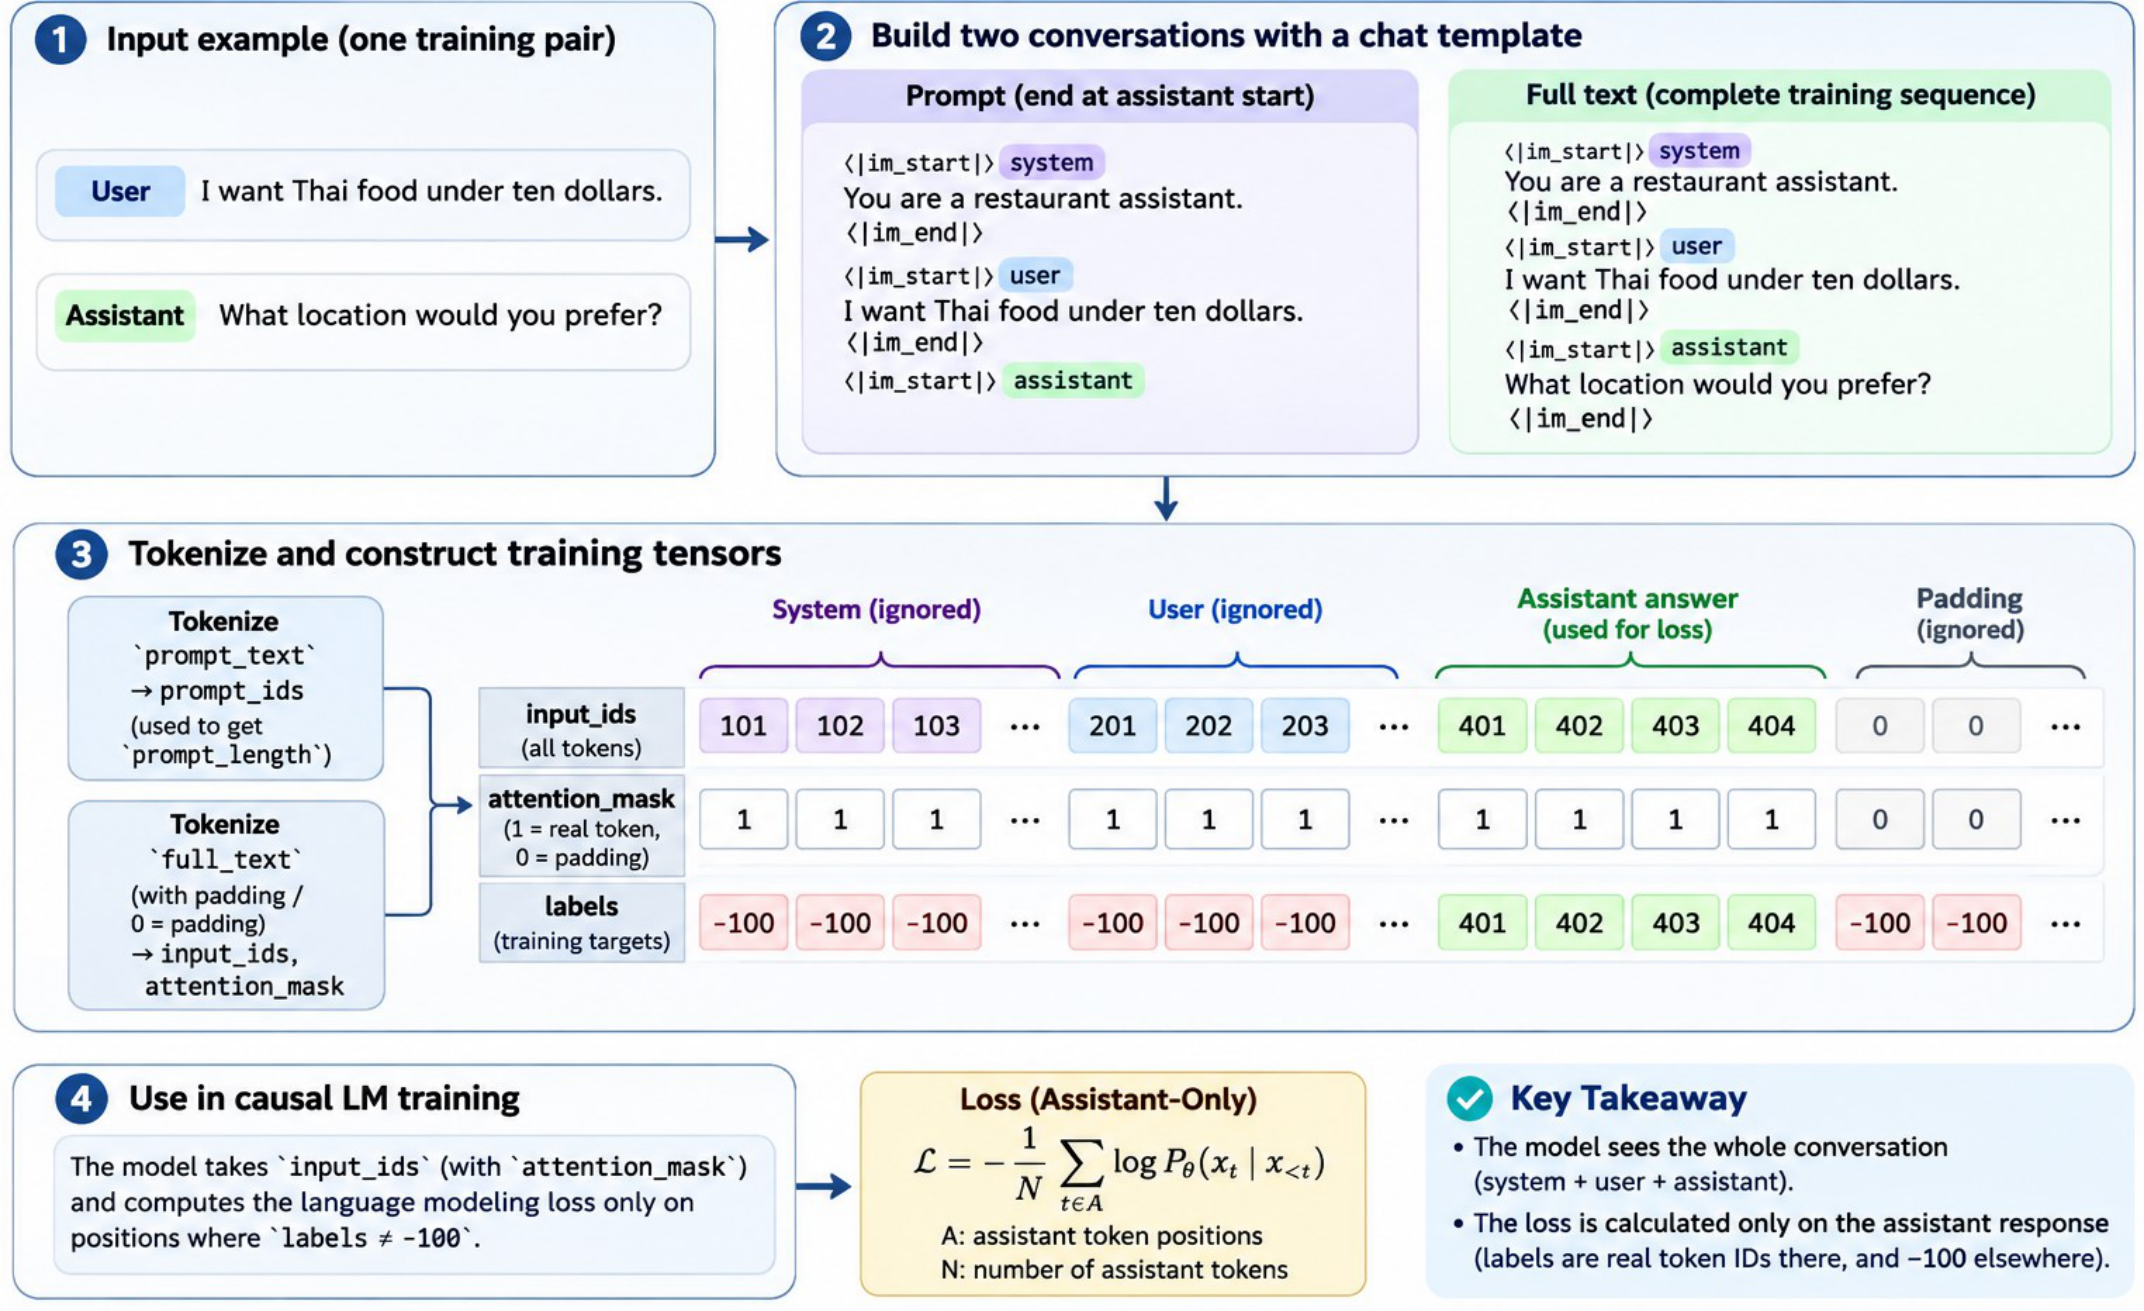


# 학습 함수


In [16]:
# 20–21쪽에 걸친 함수를 하나의 셀로 연결
def train_adapter(
    model,
    loader,
    epochs=3,
    learning_rate=2e-4
):
    optimizer = torch.optim.AdamW(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=learning_rate
    )

    model.config.use_cache = False
    model.train()

    for epoch in range(epochs):
        total_loss = 0
        for batch in loader:
            batch = {
                key: value.to(model.device)
                for key, value in batch.items()
            }
            optimizer.zero_grad()
            output = model(**batch)
            loss = output.loss
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        average_loss = total_loss / len(loader)
        print(f"Epoch {epoch+1}: "
              f"Loss = {average_loss:.4f}")

    model.config.use_cache = True


**`filter(function, iterable)`**

- `function`: 인자 하나를 받는, 조건을 판별하는 호출 가능한 함수입니다. 예를 들어 lambda 또는 이름이 있는 함수입니다.
- `iterable`: Python의 모든 iterable입니다. 리스트, 튜플, generator 또는 `model.parameters()` 등이 있습니다.

대신 다음 코드를 사용할 수 있습니다.

```python
(p for p in model.parameters() if p.requires_grad)
```

**`model.config.use_cache = False`**

Forward pass 동안 Key-Value 캐싱을 끕니다.

필요한 이유: KV 캐싱은 학습이 아니라 자기회귀 추론/생성을 위해 설계되었습니다.


**`model.config.use_cache = True`**: 학습이 끝나면 KV 캐싱을 복원하여 이후 `model.generate()` / 추론 호출에서 Key-Value 상태를 다시 효율적으로 캐싱할 수 있게 합니다.


# 파라미터 수


In [17]:
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total parameters: " f"{total:,}")
    print(f"Trainable parameters: " f"{trainable:,}")
    print(f"Trainable %: " f"{100*trainable/total:.4f}")


**`model.parameters()`**: 모델에 등록된 모든 파라미터 텐서(`torch.nn.Parameter`)를 반환합니다.

**`if p.requires_grad`**: `requires_grad` 플래그가 `True`인 파라미터 텐서만 남깁니다. 따라서 동결된 레이어, LoRA/PEFT의 기본 가중치 또는 명시적으로 동결한 파라미터는 제외됩니다.


# GPU 메모리


In [18]:
def show_gpu_memory():
    if not torch.cuda.is_available():
        return
    torch.cuda.synchronize()
    allocated = (torch.cuda.memory_allocated() / 1024**3)
    peak = (torch.cuda.max_memory_allocated() / 1024**3)
    print(f"Allocated: {allocated:.2f} GB")
    print(f"Peak:      {peak:.2f} GB")


**`torch.cuda.synchronize()`**: 측정하기 전에 현재 GPU의 대기 중인 작업이 끝날 때까지 기다립니다.

**`torch.cuda.memory_allocated()`**: 해당 GPU에서 PyTorch 텐서가 현재 차지하는 바이트 수를 반환합니다.

**`torch.cuda.max_memory_allocated()`**: 추적을 시작했거나 마지막으로 초기화한 이후 텐서 메모리가 도달한 최댓값을 반환합니다.


# 일반 FP16 Qwen 불러오기


In [19]:
# [추가] 앞부분 대화에서 불러온 모델 참조를 정리하여 중복 로딩 방지
del model
# [추가] 14쪽 예제의 계산 그래프가 모델 메모리를 붙잡지 않도록 정리
if "outputs" in globals():
    del outputs
import gc
gc.collect()

# [수정] CUDA가 없는 환경에서는 GPU 통계 초기화 생략
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.float16,
    device_map="auto"
)


**`torch.cuda.empty_cache()`**

하는 일: PyTorch의 caching allocator가 보유한 사용하지 않는 GPU 캐시 메모리를 GPU 드라이버에 반환하여 다른 프로세스 또는 이후 메모리 할당에서 사용할 수 있게 합니다.

**`torch.cuda.reset_peak_memory_stats()`**

하는 일: 기록된 최대 메모리 카운터(`max_memory_allocated()`와 `max_memory_reserved()`)를 현재 메모리 수준으로 초기화하여 다음 코드 블록에서 사용한 최대 VRAM을 별도로 측정할 수 있게 합니다.


# 기본 모델 관찰하기


In [20]:
count_parameters(model)
show_gpu_memory()


Total parameters: 1,543,714,304
Trainable parameters: 1,543,714,304
Trainable %: 100.0000


# LoRA 추가하기


In [21]:
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=["q_proj", "v_proj"],
    bias="none",
    task_type="CAUSAL_LM"
)

model = get_peft_model(
    model,
    lora_config
)

model.print_trainable_parameters()
count_parameters(model)


trainable params: 1,089,536 || all params: 1,544,803,840 || trainable%: 0.0705
Total parameters: 1,544,803,840
Trainable parameters: 1,089,536
Trainable %: 0.0705


Failed to load CPU gemm_4bit_forward from kernels-community: No module named 'kernels'. Please make sure you already `pip install kernels` and the kernels >= 0.11.1


**`r`**: LoRA rank(예: 8, 16, 32)입니다. 저랭크 분해의 병목 차원을 조절합니다.

$$
W_0 + \Delta W = W_0 + \frac{\alpha}{r}BA
$$

**`lora_alpha`**: rank $r$에 대한 adapter 업데이트의 크기를 조절하는 스케일링 계수입니다.

**`target_modules`**: LoRA adapter를 적용할 선형/투영 레이어입니다. 예를 들어 `q_proj`, `k_proj`, `v_proj`, `o_proj` 또는 MLP projection이 있습니다.

**`lora_dropout`**: 학습 중 LoRA 경로에 적용하는 dropout 확률입니다.

**`bias`**: bias 파라미터의 학습 여부입니다. `"none"`, `"all"`, `"lora_only"`가 있습니다.

**`task_type`**: 작업 종류입니다. 예를 들어 자기회귀 언어 모델은 `"CAUSAL_LM"`입니다.


# LoRA 학습


In [22]:
train_adapter(
    model,
    loader,
    epochs=3,
    learning_rate=2e-4
)
show_gpu_memory()


Epoch 1: Loss = 2.0840
Epoch 2: Loss = 1.2233
Epoch 3: Loss = 0.6853


# 테스트: 파인튜닝한 모델


In [23]:
response = chat(
    model,
    tokenizer,
    "I want cheap Thai food.",
    system_message=SYSTEM_MESSAGE,
    max_new_tokens=60,
    do_sample=False
)

print(response)


What location would you prefer?


**`do_sample=False`**

원본 모델과 파인튜닝한 모델의 차이를 확인하기 위한 설정입니다.


# 테스트: 원본 모델


In [24]:
with model.disable_adapter():
    response = chat(
        model,
        tokenizer,
        "I want cheap Thai food.",
        system_message=SYSTEM_MESSAGE,
        max_new_tokens=80,
        do_sample=False
    )

print(response)


Here are some affordable Thai restaurants in various cities:

1. **New York City:**
   - **Thai House** (20 East 4th Street, Manhattan) - Offers authentic Thai cuisine at reasonable prices.
   - **Thaipassion** (35 West 8th Street, Greenwich Village) - Known for its spicy curries and noodles.

2. **Los Angeles


`with model.disable_adapter():`는 Hugging Face `peft`의 context manager로, `with` 블록 안에서 LoRA adapter와 같은 adapter 레이어를 일시적으로 끄거나 우회합니다.


# LoRA adapter만 저장하기

15억 개 파라미터를 가진 전체 Qwen 모델을 또 하나 저장할 필요가 없습니다.

Adapter에는 작은 규모의 LoRA 파라미터가 들어 있습니다.


In [25]:
model.save_pretrained("./qwen_restaurant_lora")


# 파라미터 효율적 파인튜닝(Parameter-Efficient Fine-Tuning)

## QLoRA


# 4-bit 양자화 설정

**`prepare_model_for_kbit_training`**

무엇인가요? `get_peft_model`을 호출하기 전에 k-bit 양자화 모델(예: QLoRA를 위해 bitsandbytes로 불러온 4-bit 또는 8-bit 모델)에 적용하는 전처리 보조 함수입니다.


In [26]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
# [추가] 원문에서 누락된 BitsAndBytesConfig import
from transformers import BitsAndBytesConfig


## 4-bit 양자화 설정


In [27]:
if torch.cuda.is_bf16_supported():
    compute_dtype = torch.bfloat16
else:
    compute_dtype = torch.float16
print("Compute dtype: ", compute_dtype)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=compute_dtype,
    bnb_4bit_use_double_quant=True
)


Compute dtype:  torch.float16


| 옵션 | 의미 |
|---|---|
| `load_in_4bit=True` | 기본 가중치를 4-bit로 저장 |
| `nf4` | NormalFloat4 양자화 |
| `compute_dtype` | 연산 중 사용하는 정밀도 |
| `double_quant` | 양자화 메타데이터를 추가 압축 |


# Qwen을 4-bit로 불러오기

> **실행 안내:** 아래 코드는 원문과 동일하게 `device_map="cuda"`를 사용하므로 CUDA GPU가 필요합니다.


In [ ]:
# [추가] 앞에서 사용한 FP16 모델을 정리하여 GPU 메모리 중복 점유 방지
del model
gc.collect()

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="cuda"
)
count_parameters(model)
show_gpu_memory()


## 파라미터 수

전체 파라미터: 4-bit 가중치 두 개를 1바이트로 취급합니다.

원본 Qwen: 모든 가중치를 학습할 수 있습니다.

LoRA 적용 전 4-bit Qwen: 토큰 임베딩 행렬을 학습할 수 있습니다.  
(`233,518,592 = 151,936`개 어휘 항목 × `1,536`차원)


**PDF에 수록된 출력**

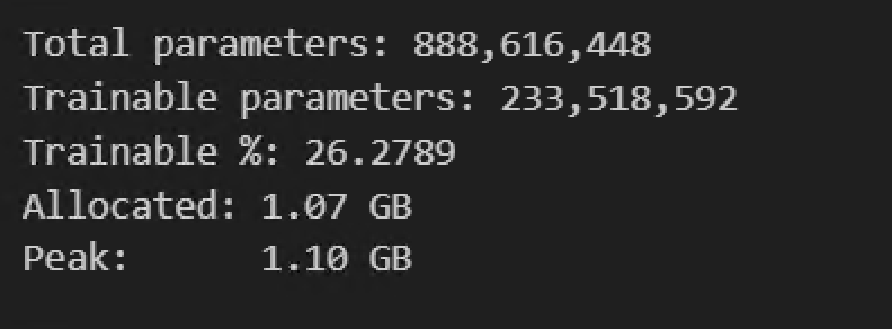


# 양자화 모델의 학습 준비

## LoRA 추가하기


**PDF에 수록된 출력**

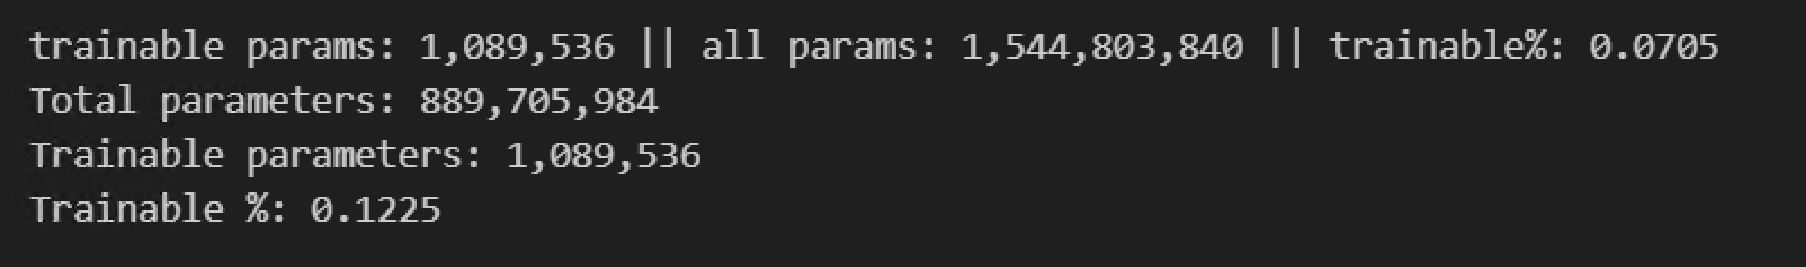


## 학습 및 평가

- 학습 가능한 LoRA 파라미터의 수는 일반 LoRA와 본질적으로 같아야 합니다.


**PDF에 수록된 출력**

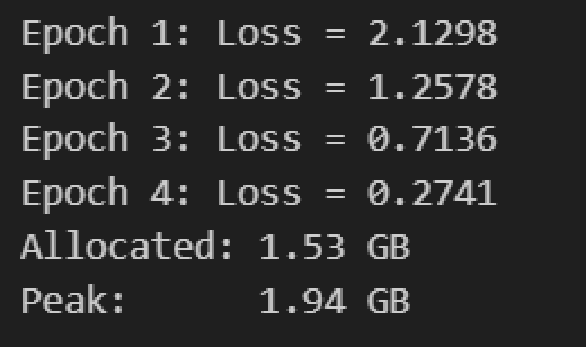


**PDF에 수록된 출력**

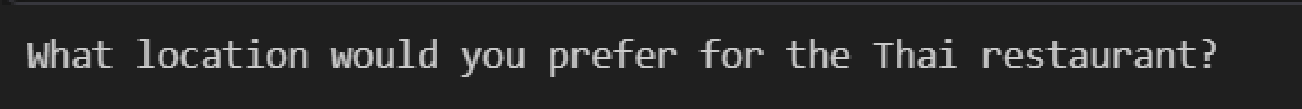


**PDF에 수록된 출력**

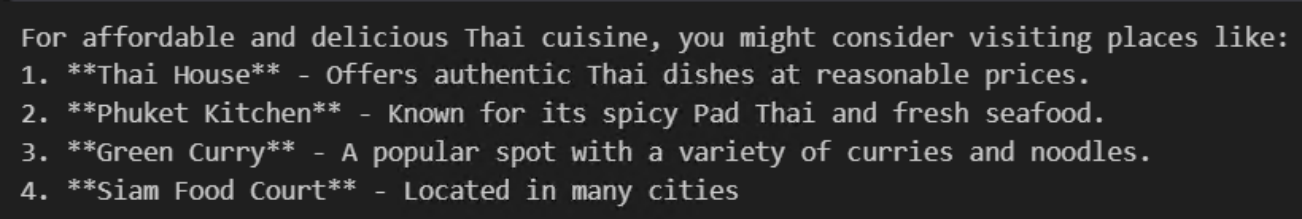


# 동일한 Qwen을 4-bit로 불러오기

**Q1. LoRA와 QLoRA에서 학습 가능한 파라미터의 수가 거의 같은 이유는 무엇인가요?**

**Q2. QLoRA에서는 무엇이 4-bit로 양자화되나요?**

**Q3. QLoRA가 동일한 적응 작업을 해결하면서 LoRA보다 GPU 메모리를 적게 사용할 수 있는 이유는 무엇인가요?**
